# 04. Optimización de hiperparámetros (Workshop S5)

1. Búsqueda en rejilla original (selección del modelo).
2. Análisis de sensibilidad: búsqueda aleatoria de 40 configuraciones + variación de un factor a la vez (28 configuraciones).
3. Modelo sustituto para ranking de importancia, dependencia parcial e interacciones.
4. Umbral de decisión y calibración.
5. Comparación antes/después.

Toda la evaluación usa validación cruzada agrupada por paciente sobre **entrenamiento**; la prueba solo se usa al final.

In [1]:
import sys, json, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.utils import cargar_config, ruta, guardar_json, leer_json
CFG = cargar_config()
FIG = ruta(CFG["rutas"]["figuras"]); MET = ruta(CFG["rutas"]["metricas"])
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
C1, C2, C3, C4 = "#1F3A5F", "#C0504D", "#7F7F7F", "#E1A93B"
def guardar(nombre):
    plt.tight_layout(); plt.savefig(FIG / nombre, bbox_inches="tight"); plt.show()
from src import optimization as opt
ENT = leer_json(MET/'entrenamiento.json')
archivo = MET/'sensibilidad_hiperparametros.csv'
if not archivo.exists() and CFG['optimizacion']['ejecutar_busqueda']:
    opt.ejecutar(CFG)          # ~20 min en un CPU
res = pd.read_csv(archivo); print(len(res), 'configuraciones evaluadas')

68 configuraciones evaluadas


## 1. Rejilla original

In [2]:
rej = pd.DataFrame(ENT['busqueda']['resultados_rejilla_gb']).sort_values('cv_auc', ascending=False)
print('mejor:', ENT['busqueda']['gb_mejores_parametros'], '| CV AUC', round(ENT['busqueda']['gb_cv3_auc'],4)); rej.round(4).head(8)

mejor: {'learning_rate': 0.1, 'max_depth': 5, 'max_iter': 100, 'min_samples_leaf': 100} | CV AUC 0.7359


,learning_rate,max_depth,max_iter,min_samples_leaf,cv_auc
13,0.10,5,100,100,0.7359
6,0.05,5,200,20,0.7357
7,0.05,5,200,100,0.7355
12,0.10,5,100,20,0.7355
5,0.05,5,100,100,0.7352
15,0.10,5,200,100,0.7352
10,0.10,3,200,20,0.7352
4,0.05,5,100,20,0.7351


## 2. Sensibilidad de un factor a la vez
Cada panel varía un hiperparámetro manteniendo los demás en la configuración final.

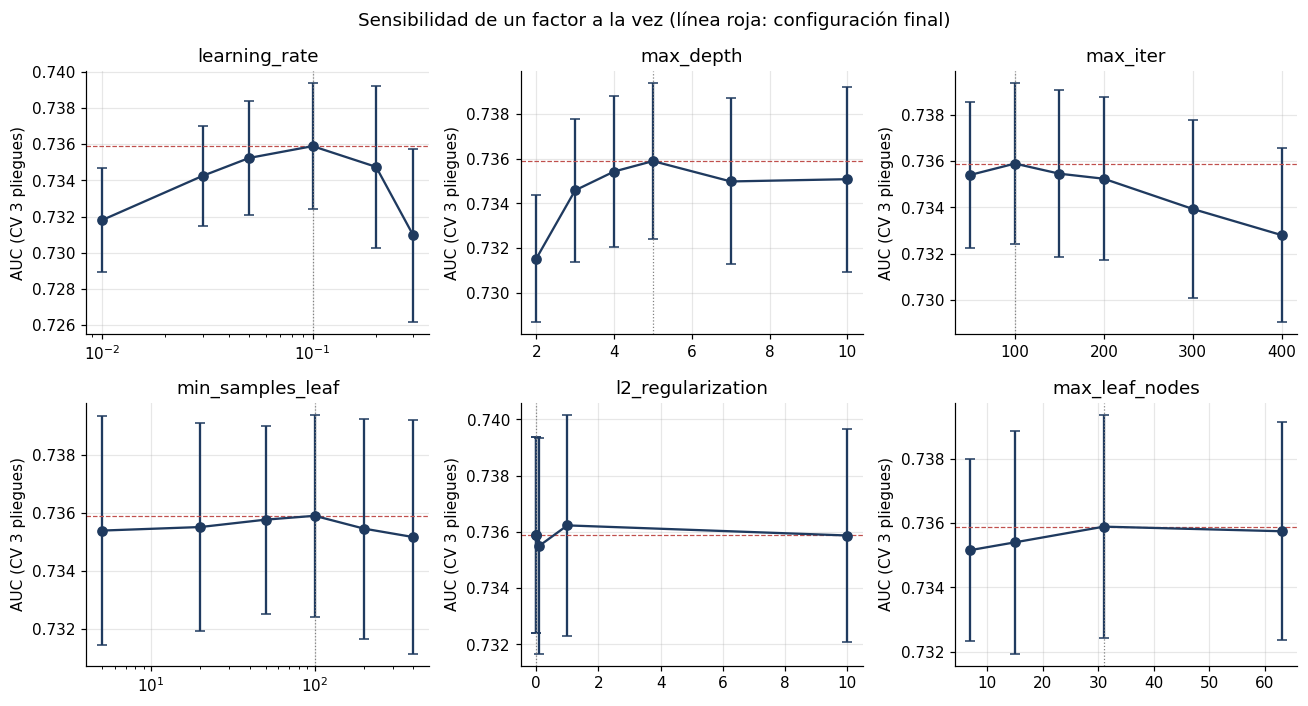

,hiperparametro,rango_auc
0,learning_rate,0.0049
1,max_depth,0.0044
2,max_iter,0.0031
3,min_samples_leaf,0.0007
5,max_leaf_nodes,0.0007
4,l2_regularization,0.0007


In [3]:
base = res[res.tipo=='base'].iloc[0]
fig, axes = plt.subplots(2,3, figsize=(12,6.5))
for ax, hp in zip(axes.ravel(), opt.HP):
    d = pd.concat([res[res.tipo==hp], res[res.tipo=='base']]).sort_values(hp)
    ax.errorbar(d[hp], d.cv_auc, yerr=d.cv_auc_de, fmt='o-', color=C1, capsize=3)
    ax.axhline(base.cv_auc, color=C2, ls='--', lw=.8); ax.axvline(base[hp], color=C3, ls=':', lw=.8)
    if hp in opt.LOG_HP and d[hp].min() > 0: ax.set_xscale('log')
    ax.set_title(hp); ax.set_ylabel('AUC (CV 3 pliegues)')
fig.suptitle('Sensibilidad de un factor a la vez (línea roja: configuración final)')
guardar('11_sensibilidad_un_factor.png')
rango = pd.DataFrame([{'hiperparametro': hp, 'rango_auc': res[res.tipo.isin([hp,'base'])].cv_auc.max() - res[res.tipo.isin([hp,'base'])].cv_auc.min()} for hp in opt.HP]).sort_values('rango_auc', ascending=False)
rango.round(4)

## 3. Ranking de importancia (modelo sustituto)
Un Random Forest aprende la relación configuración → AUC con las 68 configuraciones; la importancia por permutación en ese sustituto indica qué hiperparámetros mueven más el desempeño.

R² del sustituto (entrenamiento): 0.807


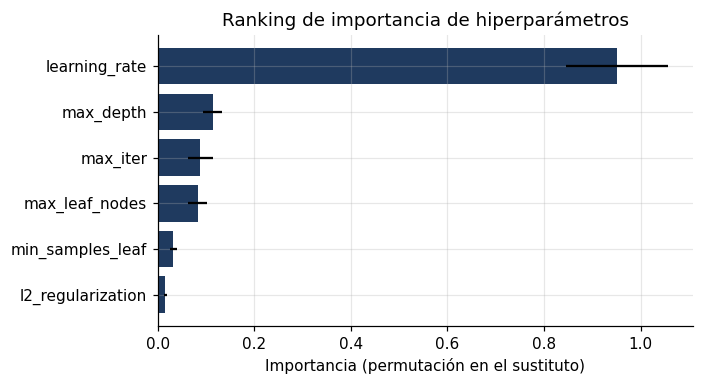

,hiperparametro,importancia,de
0,learning_rate,0.95068,0.10526
1,max_depth,0.11376,0.01993
2,max_iter,0.08783,0.02551
5,max_leaf_nodes,0.08245,0.01955
3,min_samples_leaf,0.03196,0.00768
4,l2_regularization,0.01557,0.00339


In [4]:
sust, Xs = opt.ajustar_sustituto(res)
print('R² del sustituto (entrenamiento):', round(sust.score(Xs, res.cv_auc), 3))
rank = opt.ranking_importancia(sust, Xs, res.cv_auc.values)
fig, ax = plt.subplots(figsize=(6.5,3.6)); r = rank.sort_values('importancia')
ax.barh(r.hiperparametro, r.importancia, xerr=r.de, color=C1); ax.set_xlabel('Importancia (permutación en el sustituto)'); ax.set_title('Ranking de importancia de hiperparámetros')
guardar('12_ranking_hiperparametros.png'); rank.round(5)

## 4. Dependencia parcial

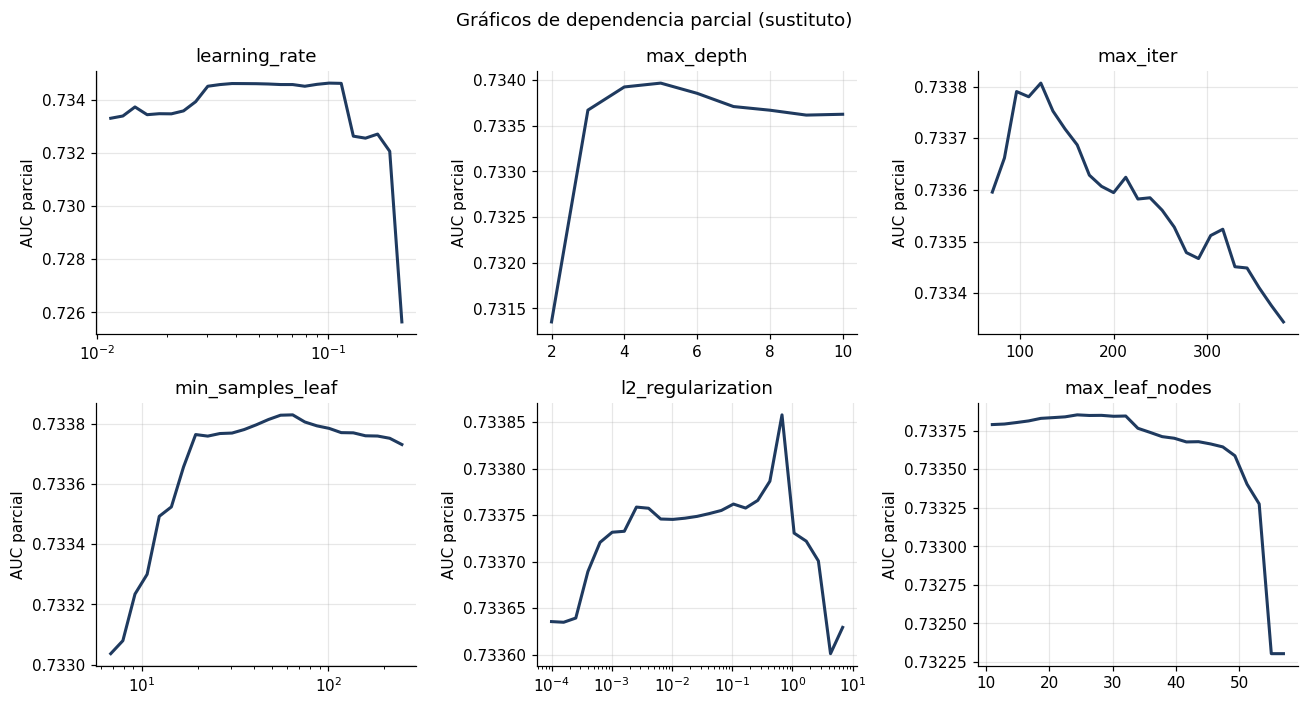

In [5]:
fig, axes = plt.subplots(2,3, figsize=(12,6.5))
for ax, hp in zip(axes.ravel(), opt.HP):
    d = opt.dependencia_parcial(sust, Xs, hp)
    ax.plot(d.valor, d.auc_parcial, color=C1, lw=2)
    if hp in opt.LOG_HP: ax.set_xscale('log')
    ax.set_title(hp); ax.set_ylabel('AUC parcial')
fig.suptitle('Gráficos de dependencia parcial (sustituto)')
guardar('13_dependencia_parcial.png')

## 5. Interacciones
Estadístico H de Friedman para cada par (0 = efectos aditivos; valores altos = interacción).

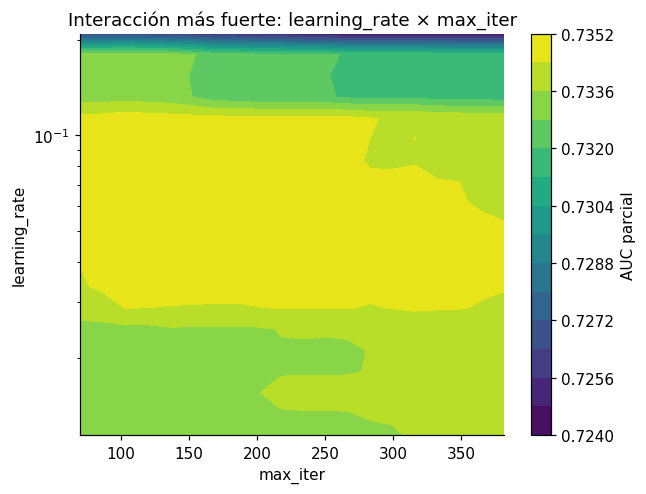

,par,H
1,learning_rate × max_iter,0.135
0,learning_rate × max_depth,0.123
4,max_depth × max_leaf_nodes,0.070
3,max_depth × max_iter,0.067
2,learning_rate × max_leaf_nodes,0.058
5,max_iter × max_leaf_nodes,0.039


In [6]:
import itertools
H = pd.DataFrame([{'par': f'{a} × {b}', 'H': opt.estadistico_h(sust, Xs, a, b)} for a, b in itertools.combinations(rank.hiperparametro.head(4), 2)]).sort_values('H', ascending=False)
top = H.iloc[0]['par'].split(' × ')
from sklearn.inspection import partial_dependence
pd2 = partial_dependence(sust, Xs, [(opt.HP.index(top[0]), opt.HP.index(top[1]))], grid_resolution=20)
g0, g1 = pd2['grid_values']
g0 = 10**g0 if top[0] in opt.LOG_HP else g0; g1 = 10**g1 if top[1] in opt.LOG_HP else g1
fig, ax = plt.subplots(figsize=(6,4.6)); cs = ax.contourf(g1, g0, pd2['average'][0], levels=15, cmap='viridis'); plt.colorbar(cs, label='AUC parcial')
if top[0] in opt.LOG_HP: ax.set_yscale('log')
if top[1] in opt.LOG_HP: ax.set_xscale('log')
ax.set_xlabel(top[1]); ax.set_ylabel(top[0]); ax.set_title(f'Interacción más fuerte: {top[0]} × {top[1]}'); ax.grid(False)
guardar('14_interaccion.png'); H.round(3)

## 6. Mejor configuración encontrada frente a la elegida

In [7]:
mejor = res.sort_values('cv_auc', ascending=False).iloc[0]
comp = pd.DataFrame({'configuración final (rejilla)': base[opt.HP + ['cv_auc','cv_auc_de']], 'mejor de la búsqueda amplia': mejor[opt.HP + ['cv_auc','cv_auc_de']]})
print('diferencia de AUC:', round(mejor.cv_auc - base.cv_auc, 4)); comp

diferencia de AUC: 0.0003


,configuración final (rejilla),mejor de la búsqueda amplia
learning_rate,0.1,0.1
max_depth,5,5
max_iter,100,100
min_samples_leaf,100,100
l2_regularization,0.0,1.0
max_leaf_nodes,31,31
cv_auc,0.73589,0.736233
cv_auc_de,0.00348,0.00393


## 7. Umbral de decisión y calibración

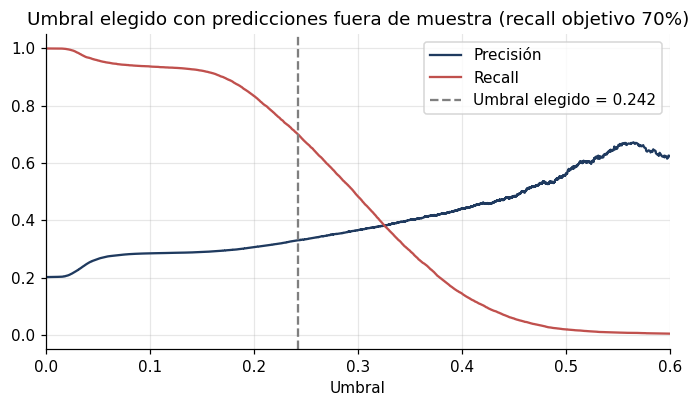

In [8]:
from sklearn.metrics import precision_recall_curve
from src.evaluate import cargar_particiones
train, test = cargar_particiones(CFG)
oof = np.load(MET/'oof_entrenamiento.npy'); thr = ENT['umbrales']['global']
pr, rc, th = precision_recall_curve(train.no_show, oof)
fig, ax = plt.subplots(figsize=(6.4,3.8)); ax.plot(th, pr[:-1], color=C1, label='Precisión'); ax.plot(th, rc[:-1], color=C2, label='Recall')
ax.axvline(thr, color=C3, ls='--', label=f'Umbral elegido = {thr:.3f}'); ax.set_xlim(0,.6); ax.set_xlabel('Umbral'); ax.legend(); ax.set_title('Umbral elegido con predicciones fuera de muestra (recall objetivo 70%)')
guardar('15_umbral.png')

## 8. Antes y después de la optimización (conjunto de prueba)

In [9]:
from src.model import ModeloRiesgo
from src.data_processing import FEATURES
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, recall_score, precision_score
filas = []
for nombre, arch in [('v1: valores por defecto, umbral 0.5', 'models/model_v1.pkl'), ('best: rejilla + umbral OOF', 'models/best_model.pkl')]:
    m = ModeloRiesgo.cargar(arch); p = m.predecir_probabilidad(test[FEATURES])
    u = 0.5 if 'v1' in nombre else m.umbral_global; pred = (p >= u).astype(int)
    filas.append({'modelo': nombre, 'AUC-ROC': roc_auc_score(test.no_show,p), 'AUC-PR': average_precision_score(test.no_show,p), 'Brier': brier_score_loss(test.no_show,p), 'umbral': u, 'recall': recall_score(test.no_show,pred), 'precisión': precision_score(test.no_show,pred,zero_division=0)})
antes_despues = pd.DataFrame(filas).round(4); antes_despues.to_csv(MET/'antes_despues_optimizacion.csv', index=False); antes_despues

,modelo,AUC-ROC,AUC-PR,Brier,umbral,recall,precisión
0,"v1: valores por defecto, umbral 0.5",0.7397,0.3757,0.1426,0.5000,0.0219,0.5728
1,best: rejilla + umbral OOF,0.7413,0.3770,0.1424,0.2424,0.7097,0.3335


In [10]:
guardar_json({'ranking': rank.to_dict(orient='records'), 'rango_un_factor': rango.to_dict(orient='records'), 'interacciones': H.to_dict(orient='records'),
             'mejor_busqueda': {k: (float(v) if isinstance(v,(int,float,np.floating,np.integer)) else v) for k,v in mejor[opt.HP+['cv_auc']].items()},
             'base': {k: float(v) for k,v in base[opt.HP+['cv_auc']].items()}, 'r2_sustituto': float(sust.score(Xs, res.cv_auc))}, MET/'optimizacion.json')

PosixPath('/home/claude/repo/priorizacion-visitas-ia/results/metrics/optimizacion.json')